# T19 · PCA cơ cấu thương mại và tăng trưởng của đối tác

**Câu hỏi.** Những trục biến thiên nào tóm tắt sự khác biệt giữa các đối tác thương mại của Việt Nam?

**Đầu vào từ T18.** Dùng 39 đối tác có kim ngạch hai chiều năm 2024 từ 1 tỷ USD và tính được CAGR 2015–2024. PCA nhận đúng 22 đặc trưng đã chuẩn hóa, gồm 21 tỷ trọng phần HS và CAGR. Mã và tên đối tác dùng để nhận diện điểm trên hình. Notebook đọc bảng z-score theo thứ tự trong danh sách đặc trưng T18.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sklearn.decomposition import PCA

input_names = ("partner_features_standardized.csv", "partner_feature_columns.csv")
root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if all((p / "data/clean" / name).is_file() for name in input_names)),
    None,
)
if root is None:
    raise FileNotFoundError("Đặt notebook trong repo có hai tệp đầu ra T18 tại data/clean/.")
clean = root / "data/clean"
data = pd.read_csv(clean / input_names[0], dtype={"partner_code": "string", "partner_iso3": "string"})
manifest = pd.read_csv(clean / input_names[1]).sort_values("feature_order")
features = manifest["feature"].tolist()
identity = ["partner_code", "partner_iso3", "partner_name"]

if (
    manifest["feature_order"].tolist() != list(range(1, len(features) + 1))
    or manifest["feature"].isna().any()
    or len(features) != len(set(features))
    or data.columns.tolist() != identity + features
    or data[identity].isna().any().any()
    or data["partner_iso3"].duplicated().any()
    or data["partner_code"].duplicated().any()
):
    raise ValueError("Kiểm tra định danh, thứ tự và danh sách đặc trưng trong đầu ra T18.")

X = data[features].to_numpy(dtype=float)
if (
    min(X.shape) < 2
    or not np.isfinite(X).all()
    or not np.allclose(X.mean(axis=0), 0, atol=1e-8)
    or not np.allclose(X.std(axis=0, ddof=0), 1, atol=1e-8)
):
    raise ValueError("T19 cần ma trận z-score hợp lệ do T18 xuất.")
print(f"Đầu vào: {X.shape[0]} đối tác × {X.shape[1]} đặc trưng z-score.")
print("Đặc trưng theo thứ tự T18:", ", ".join(features))

Đầu vào: 39 đối tác × 22 đặc trưng z-score.
Đặc trưng theo thứ tự T18: hs_i_share_pct, hs_ii_share_pct, hs_iii_share_pct, hs_iv_share_pct, hs_v_share_pct, hs_vi_share_pct, hs_vii_share_pct, hs_viii_share_pct, hs_ix_share_pct, hs_x_share_pct, hs_xi_share_pct, hs_xii_share_pct, hs_xiii_share_pct, hs_xiv_share_pct, hs_xv_share_pct, hs_xvi_share_pct, hs_xvii_share_pct, hs_xviii_share_pct, hs_xix_share_pct, hs_xx_share_pct, hs_xxi_share_pct, cagr_pct


## 1. Phương sai giải thích

PCA dùng SVD đầy đủ để tính tất cả thành phần. Để hướng của trục dễ tái lập khi trình bày, mỗi PC được định hướng sao cho hệ số có trị tuyệt đối lớn nhất mang dấu dương. Đổi dấu đồng thời điểm và hệ số tải chỉ đảo chiều trục.

In [2]:
pca = PCA(svd_solver="full").fit(X)
signs = np.where(pca.components_[np.arange(len(pca.components_)),
                                   np.abs(pca.components_).argmax(axis=1)] < 0, -1, 1)
scores = pca.transform(X) * signs
weights = pca.components_.T * signs
percent = 100 * pca.explained_variance_ratio_
cumulative = percent.cumsum()
rank = np.linalg.matrix_rank(X - X.mean(axis=0))

if not np.isclose(percent.sum(), 100) or not np.allclose(
    scores.var(axis=0, ddof=1), pca.explained_variance_
):
    raise ValueError("Phương sai của điểm PCA không khớp kết quả phân rã.")
variance_table = pd.DataFrame({"PC": np.arange(1, len(percent)+1),
                               "Riêng lẻ (%)": percent, "Tích lũy (%)": cumulative})
print(variance_table.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print(f"PC1–PC2 giữ {cumulative[1]:.2f}%; phần còn lại {100-cumulative[1]:.2f}%.")
print(f"Hạng ma trận sau định tâm: {rank}.")

 PC  Riêng lẻ (%)  Tích lũy (%)
  1         17.41         17.41
  2         14.34         31.75
  3          9.74         41.48
  4          9.04         50.52
  5          6.75         57.28
  6          5.37         62.64
  7          4.98         67.62
  8          4.87         72.49
  9          4.04         76.53
 10          3.91         80.45
 11          3.40         83.85
 12          3.31         87.16
 13          2.81         89.97
 14          2.17         92.14
 15          2.00         94.14
 16          1.73         95.87
 17          1.51         97.38
 18          1.24         98.62
 19          0.79         99.41
 20          0.41         99.81
 21          0.19        100.00
 22          0.00        100.00
PC1–PC2 giữ 31.75%; phần còn lại 68.25%.
Hạng ma trận sau định tâm: 21.


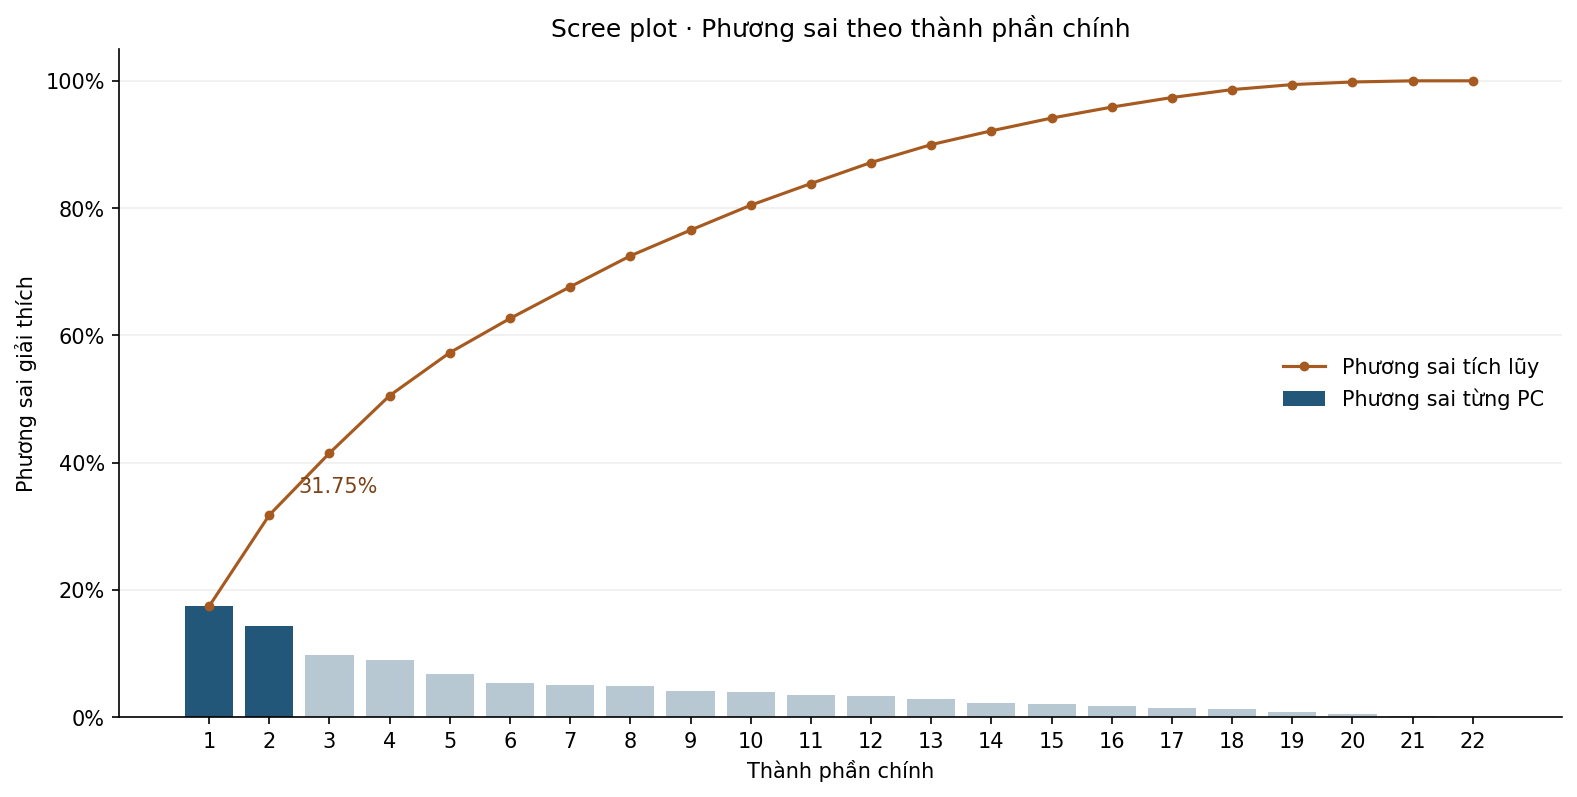

In [3]:
with plt.rc_context({"font.family": "DejaVu Sans", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.axisbelow": True}):
    figure_output, ax = plt.subplots(figsize=(10.4, 5.2), layout="constrained")
    pc = variance_table["PC"]
    ax.bar(pc, percent, color=["#22577A" if i <= 2 else "#B8C8D2" for i in pc],
           label="Phương sai từng PC")
    ax.plot(pc, cumulative, "o-", color="#A65A20", markersize=3.7,
            label="Phương sai tích lũy")
    ax.annotate(f"{cumulative[1]:.2f}%", (2, cumulative[1]), xytext=(14, 11),
                textcoords="offset points", color="#7C4318")
    ax.set(xlabel="Thành phần chính", ylabel="Phương sai giải thích",
           xticks=pc, ylim=(0, 105), title="Scree plot · Phương sai theo thành phần chính")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.grid(axis="y", alpha=.2)
    ax.legend(loc="center right", frameon=False)
    plt.show()

## 2. Biplot PC1–PC2

Dùng **biplot đối xứng từ SVD**. Với giá trị kỳ dị $s_k$, tọa độ đối tác trên PC $k$ bằng điểm PCA chia $\sqrt{s_k}$ và tọa độ đầu mũi tên bằng hệ số tải nhân $\sqrt{s_k}$. Phép đổi thang giữ tích vô hướng giữa điểm và mũi tên bằng giá trị z-score tái dựng bởi hai PC. Cả hai trục dùng cùng tỷ lệ hiển thị.

Hình có đủ đối tác. Gắn nhãn ISO3 cho hai đầu mỗi trục và một số đối tác tiêu biểu. Để dễ đọc, hình chỉ vẽ hợp của ba hệ số tải lớn nhất về trị tuyệt đối trên mỗi PC. Bảng dưới in đủ hệ số tải của 22 đặc trưng, lấy từ vector riêng có độ dài bằng 1. Các hệ số trong bảng dùng để đọc dấu và độ lớn trong từng PC.

                      PC1    PC2
hs_i_share_pct     +0.037 +0.106
hs_ii_share_pct    -0.009 -0.232
hs_iii_share_pct   +0.257 -0.219
hs_iv_share_pct    +0.009 -0.125
hs_v_share_pct     +0.147 -0.247
hs_vi_share_pct    +0.405 +0.152
hs_vii_share_pct   +0.242 -0.143
hs_viii_share_pct  +0.057 +0.349
hs_ix_share_pct    +0.285 +0.136
hs_x_share_pct     +0.278 -0.113
hs_xi_share_pct    -0.002 +0.390
hs_xii_share_pct   -0.115 +0.435
hs_xiii_share_pct  +0.243 -0.020
hs_xiv_share_pct   +0.124 +0.204
hs_xv_share_pct    +0.354 -0.024
hs_xvi_share_pct   -0.299 -0.009
hs_xvii_share_pct  +0.254 -0.036
hs_xviii_share_pct +0.221 +0.249
hs_xix_share_pct   -0.180 -0.015
hs_xx_share_pct    -0.091 +0.282
hs_xxi_share_pct   +0.033 +0.258
cagr_pct           -0.261 -0.146


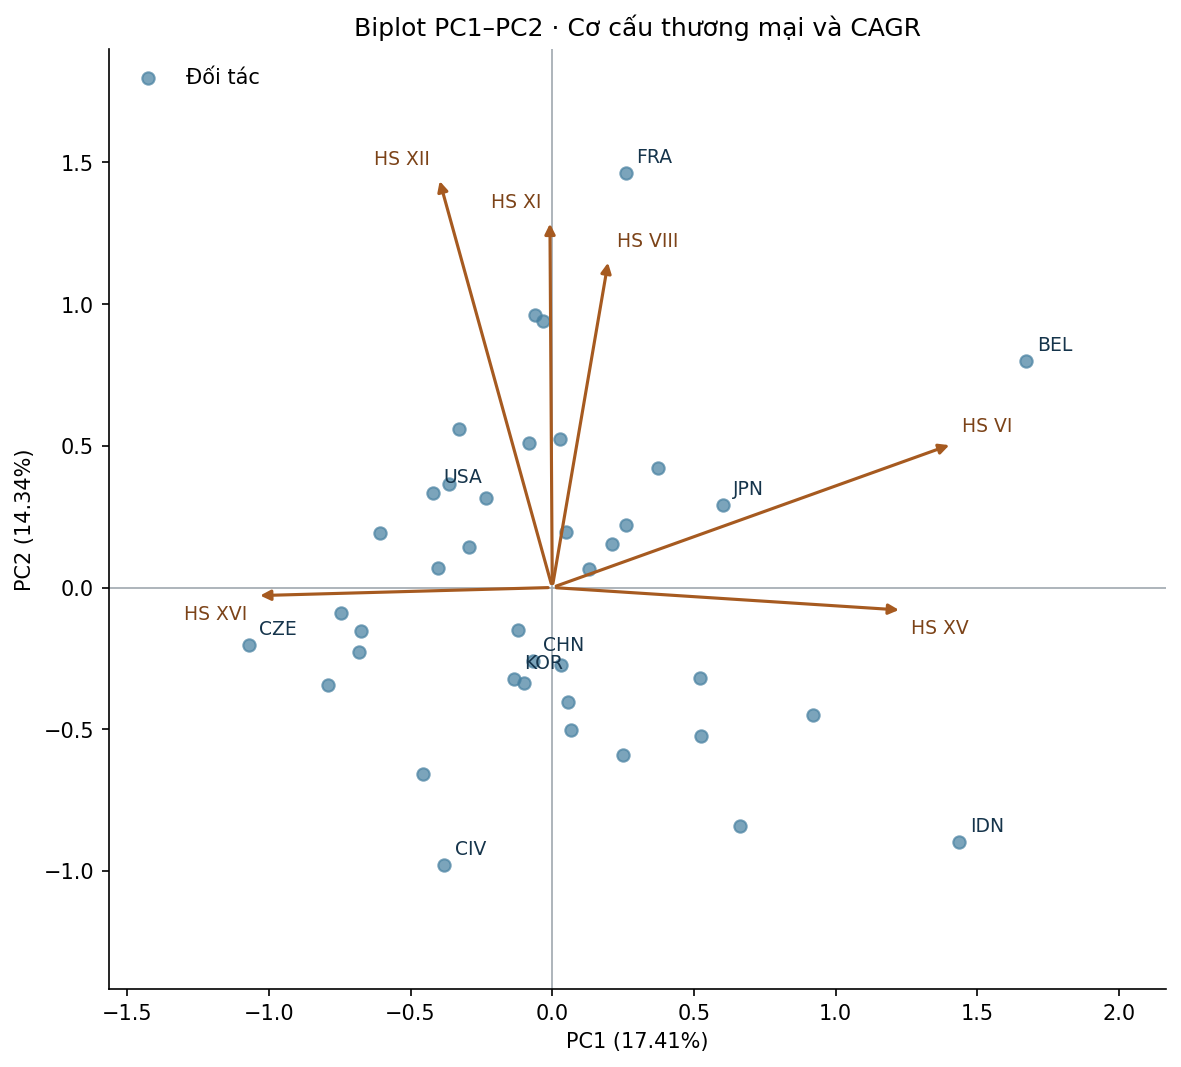

In [4]:
loadings = pd.DataFrame(weights[:, :2], index=features, columns=["PC1", "PC2"])
print(loadings.to_string(float_format=lambda v: f"{v:+.3f}"))

scales = np.sqrt(pca.singular_values_[:2])
points = scores[:, :2] / scales
arrows = weights[:, :2] * scales
assert np.allclose(points @ arrows.T, scores[:, :2] @ weights[:, :2].T)
arrow_features = list(dict.fromkeys(
    feature for pc in ("PC1", "PC2") for feature in loadings[pc].abs().nlargest(3).index
))
partner_labels = set(data.index[data["partner_iso3"].isin(["CHN", "USA", "KOR", "JPN", "IDN"])])
for k in range(2):
    partner_labels.update([points[:, k].argmin(), points[:, k].argmax()])

with plt.rc_context({"font.family": "DejaVu Sans", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.axisbelow": True}):
    figure_output, ax = plt.subplots(figsize=(10, 7), layout="constrained")
    ax.axhline(0, color="#A0A8AF", linewidth=.8)
    ax.axvline(0, color="#A0A8AF", linewidth=.8)
    ax.scatter(*points.T, s=35, color="#4881A1", alpha=.72, label="Đối tác")
    for i in sorted(partner_labels):
        ax.annotate(data.loc[i, "partner_iso3"], points[i], xytext=(5, 5),
                    textcoords="offset points", fontsize=9, color="#15344B")
    for feature in arrow_features:
        x, y = arrows[features.index(feature)]
        name = "CAGR" if feature == "cagr_pct" else "HS " + feature.split("_")[1].upper()
        ax.annotate("", xy=(x, y), xytext=(0, 0),
                    arrowprops={"arrowstyle": "-|>", "color": "#A65A20", "lw": 1.5})
        ax.annotate(name, (x, y), xytext=(4 if x >= 0 else -4, 4 if y >= 0 else -4),
                    textcoords="offset points", ha="left" if x >= 0 else "right",
                    va="bottom" if y >= 0 else "top", fontsize=9, color="#7C4318",
                    bbox={"facecolor":"white","edgecolor":"none","alpha":.86,"pad":.5})
    ax.set(xlabel=f"PC1 ({percent[0]:.2f}%)", ylabel=f"PC2 ({percent[1]:.2f}%)",
           title="Biplot PC1–PC2 · Cơ cấu thương mại và CAGR")
    ax.set_aspect("equal", adjustable="box")
    ax.margins(.18)
    ax.legend(loc="upper left", frameon=False)
    plt.show()

## 3. Diễn giải kết quả

**PC1 (17.41%)** đối chiếu tỷ trọng hóa chất HS VI (+0.405), kim loại cơ bản HS XV (+0.354) và gỗ HS IX (+0.285) ở phía dương với máy móc, thiết bị điện HS XVI (−0.299) và CAGR (−0.261) ở phía âm. Bỉ và Indonesia có điểm PC1 cao, còn Séc có điểm thấp nhất trên trục này. **PC2 (14.34%)** nghiêng về giày dép và nhóm mặt hàng cùng phần HS XII (+0.435), dệt may HS XI (+0.390), da và sản phẩm da HS VIII (+0.349), đối lập với phía có tải âm của khoáng sản HS V (−0.247), sản phẩm thực vật HS II (−0.232) và dầu mỡ HS III (−0.219). Pháp có điểm PC2 cao nhất, còn Côte d’Ivoire nằm ở đầu thấp của trục. **Hai PC giữ 31.75% phương sai** của ma trận z-score, nên **68.25%** nằm ở các thành phần còn lại và khoảng cách trên biplot chỉ phản ánh phần biến thiên được chiếu lên hai trục.

*Ghi chú khi trình bày.* Ba cột định danh nằm ngoài PCA. Tổng 21 tỷ trọng HS bằng 100%, nên có một ràng buộc tuyến tính và hạng ma trận là 21. Các mẫu hình mô tả bộ 39 đối tác theo tiêu chí T18.